In [1]:

from pathlib import Path

PROJECT = Path("/content/lifeguard_test")

for folder in ["videos", "annotations", "frames"]:
    path = PROJECT / folder

    print(f"\n--- {folder} ---")

    if path.exists():
        files = list(path.iterdir())
        print("Files:", len(files))

        for file in files[:10]:
            print(file.name)
    else:
        print("Folder not found")



--- videos ---
Files: 2
Z9npOp9WhWM.mp4
XPPOcJNk1S8.mp4

--- annotations ---
Files: 2
XPPOcJNk1S8.xml
Z9npOp9WhWM.xml

--- frames ---
Files: 2
XPPOcJNk1S8
Z9npOp9WhWM


In [2]:
# Cell 1 — Setup and a safe download helper.
import os, urllib.request, urllib.error

BASE = "/content/lifeguard_test"
RAW  = "https://raw.githubusercontent.com/Z5cc/drowning-detection/master/"
os.makedirs(BASE, exist_ok=True)

def download(url, dest, expected=None):
    """Download one file. Skips it if it already exists and is non-empty
    (so your two existing XMLs/videos/frames are never overwritten)."""
    if os.path.exists(dest) and os.path.getsize(dest) > 0:
        print("SKIP (already present):", dest)
        return 0
    try:
        req = urllib.request.Request(url, headers={"User-Agent": "colab-dataset-prep"})
        with urllib.request.urlopen(req, timeout=60) as r:
            data = r.read()
    except urllib.error.HTTPError as e:
        print(f"ERROR {e.code}: {url}")
        return -1
    except Exception as e:
        print(f"ERROR {type(e).__name__}: {url}")
        return -1
    os.makedirs(os.path.dirname(dest), exist_ok=True)
    with open(dest, "wb") as f:
        f.write(data)
    print(f"OK {dest} ({len(data)} bytes)")
    if expected is not None and len(data) != expected:
        print(f"  WARNING: size {len(data)} != expected {expected}")
    return len(data)

In [3]:
# Cell 2 — The manifest table: maps every clip to video id + start/end + crop.
# Verified size from the repo: 6,550 bytes.
download(RAW + "dataset_lifeguard/datalist.csv",
         f"{BASE}/datalist.csv", expected=6550)

OK /content/lifeguard_test/datalist.csv (6550 bytes)


6550

In [4]:
# Cell 3 — All temporal swim/drown annotations (91 XMLs in repo; you already have 2).
import json

API = "https://api.github.com/repos/Z5cc/drowning-detection/git/trees/master?recursive=1"
req = urllib.request.Request(API, headers={"User-Agent": "colab-dataset-prep"})
with urllib.request.urlopen(req, timeout=60) as r:
    tree = json.load(r)

size_by_path = {e["path"]: e["size"] for e in tree["tree"] if e["type"] == "blob"}
label_paths = [p for p in size_by_path
               if p.startswith("dataset_lifeguard/labels/") and p.endswith(".xml")]

downloaded = skipped = errors = total = 0
for p in sorted(label_paths):
    dest = f"{BASE}/annotations/{p.split('/')[-1]}"
    n = download(RAW + p, dest, expected=size_by_path[p])
    if n == 0:   skipped += 1
    elif n < 0:  errors += 1
    else:        downloaded += 1; total += n

print(f"\nLabels: {downloaded} downloaded ({total/1e6:.2f} MB), {skipped} already present, {errors} errors.")

OK /content/lifeguard_test/annotations/0hBJ0gd9T_U_00-00-08--00-00-20_0-40--0-20--0-17.xml (111973 bytes)
OK /content/lifeguard_test/annotations/1WIDSrr_1lk_00-00-20--00-00-31_0-58--0-23--0-13.xml (67391 bytes)
OK /content/lifeguard_test/annotations/1_l6-wMAvaA_00-00-14--00-00-33_0-54--0-34--0-19.xml (115404 bytes)
OK /content/lifeguard_test/annotations/4sFuULOY5ik_00-00-12--00-00-22_0-54--0-25--0-07.xml (91296 bytes)
OK /content/lifeguard_test/annotations/5YHUlEP7auA_00-00-07--00-00-17_0-55--0-23--0-11.xml (72866 bytes)
OK /content/lifeguard_test/annotations/5rxH_ELrwTU_00-00-00--00-00-14_0-00--0-32--0-52.xml (173445 bytes)
OK /content/lifeguard_test/annotations/5rxH_ELrwTU_00-00-43--00-01-02_0-64--0-14--0-29.xml (101016 bytes)
OK /content/lifeguard_test/annotations/6H8IKoacICU_00-00-07--00-00-17_0-20--0-25--0-11.xml (86207 bytes)
OK /content/lifeguard_test/annotations/82PyW_G61MU_00-00-11--00-00-22_0-62--0-30--0-17.xml (63861 bytes)
OK /content/lifeguard_test/annotations/9uJazpj9xPw_

In [5]:
# Cell 4 — The author's train/test splits (9 folds + final + difficult).
# Uses `size_by_path` from Cell 3, so run the cells in order.
split_paths = [p for p in size_by_path
               if "splitlists" in p and p.endswith(".csv")]

for p in sorted(split_paths):
    download(RAW + p, f"{BASE}/splitlists/{p.split('/')[-1]}", expected=size_by_path[p])

print("Split lists saved under", f"{BASE}/splitlists/")

OK /content/lifeguard_test/splitlists/1_test.csv (500 bytes)
OK /content/lifeguard_test/splitlists/1_train.csv (3887 bytes)
OK /content/lifeguard_test/splitlists/2_test.csv (500 bytes)
OK /content/lifeguard_test/splitlists/2_train.csv (3887 bytes)
OK /content/lifeguard_test/splitlists/3_test.csv (500 bytes)
OK /content/lifeguard_test/splitlists/3_train.csv (3887 bytes)
OK /content/lifeguard_test/splitlists/4_test.csv (500 bytes)
OK /content/lifeguard_test/splitlists/4_train.csv (3887 bytes)
OK /content/lifeguard_test/splitlists/5_test.csv (500 bytes)
OK /content/lifeguard_test/splitlists/5_train.csv (3887 bytes)
OK /content/lifeguard_test/splitlists/6_test.csv (500 bytes)
OK /content/lifeguard_test/splitlists/6_train.csv (3887 bytes)
OK /content/lifeguard_test/splitlists/7_test.csv (500 bytes)
OK /content/lifeguard_test/splitlists/7_train.csv (3887 bytes)
OK /content/lifeguard_test/splitlists/8_test.csv (500 bytes)
OK /content/lifeguard_test/splitlists/8_train.csv (3887 bytes)
OK /cont

In [6]:
# Cell 1 — Parse all annotation XMLs and summarize (read-only)
import os, glob
import xml.etree.ElementTree as ET
import pandas as pd

BASE = "/content/lifeguard_test"
xml_files = sorted(glob.glob(f"{BASE}/annotations/*.xml"))

box_counts = {"swim": 0, "drown": 0}
frame_with = {"swim": 0, "drown": 0}
file_with  = {"swim": 0, "drown": 0}
tot_frames = 0
unexpected = {}        # any label that is not swim/drown
parse_failed = []      # files that could not be read
id_gaps = []           # files where frame ids are not 0,1,2,3...

for path in xml_files:
    name = os.path.basename(path)
    try:
        root = ET.parse(path).getroot()
    except Exception as e:
        parse_failed.append((name, str(e)))
        continue

    sw = dw = sw_f = dw_f = 0
    last = -1
    for im in root.iter("image"):
        tot_frames += 1
        iid = int(im.get("id"))
        if iid != last + 1:
            id_gaps.append((name, last, iid))   # frame order is broken here
        last = iid
        s = d = False
        for b in im.iter("box"):
            lab = b.get("label")
            if lab == "swim":   sw += 1; s = True
            elif lab == "drown": dw += 1; d = True
            else: unexpected[lab] = unexpected.get(lab, 0) + 1
        if s: sw_f += 1
        if d: dw_f += 1

    box_counts["swim"] += sw; box_counts["drown"] += dw
    frame_with["swim"] += sw_f; frame_with["drown"] += dw_f
    if sw: file_with["swim"] += 1
    if dw: file_with["drown"] += 1

table = pd.DataFrame([
    ["Annotation files found", len(xml_files)],
    ["Files with parse error", len(parse_failed)],
    ["Total annotated frames", tot_frames],
    ["swim  bounding boxes", box_counts["swim"]],
    ["drown bounding boxes", box_counts["drown"]],
    ["Frames containing swim", frame_with["swim"]],
    ["Frames containing drown", frame_with["drown"]],
    ["Files containing swim", file_with["swim"]],
    ["Files containing drown", file_with["drown"]],
], columns=["Metric", "Value"])

print(table.to_string(index=False))
print("\nUnexpected labels:", unexpected or "none")
print("Frame-id gaps (order broken):", id_gaps or "none")
print("Parse failures:", parse_failed or "none")

                 Metric  Value
 Annotation files found     93
 Files with parse error      0
 Total annotated frames  48878
   swim  bounding boxes  76018
   drown bounding boxes  25269
 Frames containing swim  34038
Frames containing drown  24079
  Files containing swim     71
 Files containing drown     57

Unexpected labels: none
Frame-id gaps (order broken): none
Parse failures: none


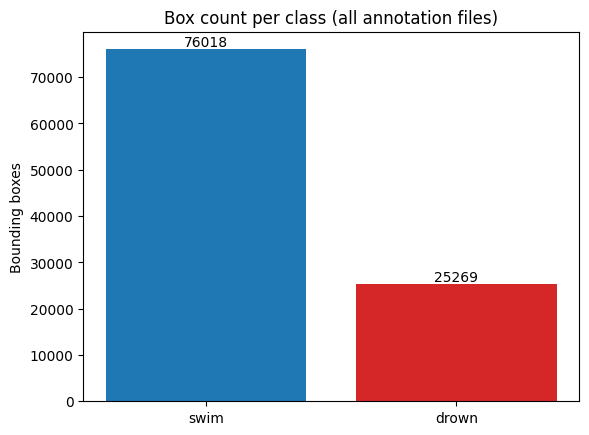

In [7]:
# Cell 2 — Bar chart: swim vs drown box counts
import matplotlib.pyplot as plt

labels = ["swim", "drown"]
values = [box_counts["swim"], box_counts["drown"]]

plt.bar(labels, values, color=["#1f77b4", "#d62728"])
plt.ylabel("Bounding boxes")
plt.title("Box count per class (all annotation files)")
for i, v in enumerate(values):
    plt.text(i, v, str(v), ha="center", va="bottom")
plt.show()

In [8]:
# Cell 3 — Inspect the train/test split CSVs
import csv, glob

split_files = sorted(glob.glob(f"{BASE}/splitlists/*.csv"))
print("Split files found:", len(split_files), "\n")

for f in split_files:
    with open(f, newline="") as fh:
        rows = list(csv.reader(fh))
    ncols = max((len(r) for r in rows), default=0)
    print(f"{os.path.basename(f):24s} lines={len(rows):3d}  columns={ncols}")

print("\nPreview of train.csv (1 column = clip id):")
with open(f"{BASE}/splitlists/train.csv", newline="") as fh:
    for row in list(csv.reader(fh))[:3]:
        print("  ", row)

print("\nPreview of test.csv (2 columns = clip id, drown flag):")
with open(f"{BASE}/splitlists/test.csv", newline="") as fh:
    for row in list(csv.reader(fh))[:5]:
        print("  ", row)

Split files found: 22 

1_test.csv               lines= 10  columns=2
1_train.csv              lines= 81  columns=1
2_test.csv               lines= 10  columns=2
2_train.csv              lines= 81  columns=1
3_test.csv               lines= 10  columns=2
3_train.csv              lines= 81  columns=1
4_test.csv               lines= 10  columns=2
4_train.csv              lines= 81  columns=1
5_test.csv               lines= 10  columns=2
5_train.csv              lines= 81  columns=1
6_test.csv               lines= 10  columns=2
6_train.csv              lines= 81  columns=1
7_test.csv               lines= 10  columns=2
7_train.csv              lines= 81  columns=1
8_test.csv               lines= 10  columns=2
8_train.csv              lines= 81  columns=1
9_test.csv               lines= 11  columns=2
9_train.csv              lines= 80  columns=1
difficult_test.csv       lines=  7  columns=1
difficult_train.csv      lines= 91  columns=1
test.csv                 lines=  9  columns=2
train.csv 

In [9]:
# Cell 4 — Which annotation clips match the two videos/frames already on disk?
videos = sorted(glob.glob(f"{BASE}/videos/*.mp4"))
xml_names = [os.path.basename(p) for p in xml_files]

for v in videos:
    vname = os.path.splitext(os.path.basename(v))[0]
    matches = [n for n in xml_names if n.startswith(vname + "_")]
    print(f"\n{vname}.mp4  -> {len(matches)} annotation clip(s):")
    for m in matches:
        root = ET.parse(f"{BASE}/annotations/{m}").getroot()
        n = sum(1 for _ in root.iter("image"))
        print(f"    {m}  ({n} annotated frames)")
    fdir = f"{BASE}/frames/{vname}"
    extracted = len(glob.glob(f"{fdir}/*.jpg")) if os.path.isdir(fdir) else 0
    print(f"  extracted frames on disk: {extracted}")


XPPOcJNk1S8.mp4  -> 1 annotation clip(s):
    XPPOcJNk1S8_00-00-05--00-00-20_0-70--0-27--0-11.xml  (449 annotated frames)
  extracted frames on disk: 450

Z9npOp9WhWM.mp4  -> 3 annotation clip(s):
    Z9npOp9WhWM_00-00-00--00-00-13_0-56--0-32--0-66.xml  (418 annotated frames)
    Z9npOp9WhWM_00-00-04--00-00-15_0-46--0-32--0-66.xml  (334 annotated frames)
    Z9npOp9WhWM_00-00-22--00-00-34_0-04--0-25--0-17.xml  (359 annotated frames)
  extracted frames on disk: 359


In [10]:
# Cell 1 — Load all split CSVs and inspect their columns
import os, glob, csv, re

BASE = "/content/lifeguard_test"

def read_csv(path):
    with open(path, newline="") as f:
        return list(csv.reader(f))

def video_id_of(snippet):
    # snippet = "videoId_00-00-15--00-00-25_0-46--0-33--0-12"
    m = re.match(r"^(.*?)_\d{2}-\d{2}-\d{2}--\d{2}-\d{2}-\d{2}_", snippet)
    return m.group(1) if m else "?"

files = sorted(glob.glob(f"{BASE}/splitlists/*.csv"))
print("Split files:", len(files), "\n")
for f in files:
    rows = read_csv(f)
    ncols = max((len(r) for r in rows), default=0)
    print(f"{os.path.basename(f):24s} rows={len(rows):3d}  columns={ncols}")

print("\nPreview train.csv (1 column = clip id):")
for r in read_csv(f"{BASE}/splitlists/train.csv")[:3]:
    print("  ", r)
print("Preview test.csv (2 columns = clip id, d/s flag):")
for r in read_csv(f"{BASE}/splitlists/test.csv")[:5]:
    print("  ", r)

Split files: 22 

1_test.csv               rows= 10  columns=2
1_train.csv              rows= 81  columns=1
2_test.csv               rows= 10  columns=2
2_train.csv              rows= 81  columns=1
3_test.csv               rows= 10  columns=2
3_train.csv              rows= 81  columns=1
4_test.csv               rows= 10  columns=2
4_train.csv              rows= 81  columns=1
5_test.csv               rows= 10  columns=2
5_train.csv              rows= 81  columns=1
6_test.csv               rows= 10  columns=2
6_train.csv              rows= 81  columns=1
7_test.csv               rows= 10  columns=2
7_train.csv              rows= 81  columns=1
8_test.csv               rows= 10  columns=2
8_train.csv              rows= 81  columns=1
9_test.csv               rows= 11  columns=2
9_train.csv              rows= 80  columns=1
difficult_test.csv       rows=  7  columns=1
difficult_train.csv      rows= 91  columns=1
test.csv                 rows=  9  columns=2
train.csv                rows= 82  co

In [11]:
# Cell 2 — Distribution of 'd' vs 's' in every two-column (test) file
from collections import Counter

print("Test files: 'd' = clip contains drown, 's' = swim-only")
for f in files:
    rows = read_csv(f)
    if rows and len(rows[0]) >= 2:
        c = Counter(r[1] for r in rows if len(r) >= 2)
        print(f"  {os.path.basename(f):24s} {dict(c)}")

Test files: 'd' = clip contains drown, 's' = swim-only
  1_test.csv               {'d': 8, 's': 2}
  2_test.csv               {'d': 6, 's': 4}
  3_test.csv               {'d': 8, 's': 2}
  4_test.csv               {'d': 5, 's': 5}
  5_test.csv               {'s': 5, 'd': 5}
  6_test.csv               {'s': 3, 'd': 7}
  7_test.csv               {'d': 6, 's': 4}
  8_test.csv               {'s': 6, 'd': 4}
  9_test.csv               {'s': 5, 'd': 6}
  test.csv                 {'d': 6, 's': 3}


In [12]:
# Cell 3 — Missing references and orphan annotations
xml_base = {os.path.splitext(os.path.basename(p))[0]
            for p in glob.glob(f"{BASE}/annotations/*.xml")}

all_clips = set()
for f in files:
    for r in read_csv(f):
        if r:
            all_clips.add(r[0])

missing = sorted(c for c in all_clips if c not in xml_base)   # in splits, no XML
orphans = sorted(x for x in xml_base if x not in all_clips)   # XML, not in any split

print("XML annotation files:", len(xml_base))
print("Distinct clip IDs across all splits:", len(all_clips))
print("\nSplit clip IDs with NO matching XML:", len(missing))
for c in missing[:20]: print("  ", c)
print("\nXMLs NOT referenced by any split file:", len(orphans))
for x in orphans[:20]: print("  ", x)

XML annotation files: 93
Distinct clip IDs across all splits: 98

Split clip IDs with NO matching XML: 7
   MoIdJ8a9D0Y_00-00-00--00-00-44_0-09--0-08--0-55
   MoIdJ8a9D0Y_00-00-58--00-01-23_0-61--0-27--0-38
   YgUglYhVSkk_00-00-00--00-00-15_0-06--0-20--0-67
   _adf2ZJtV3g_00-00-15--00-00-42_0-26--0-18--0-67
   i6XeI_NRis4_00-00-00--00-00-20_0-44--0-08--0-75
   i6XeI_NRis4_00-00-40--00-01-56_0-19--0-03--0-95
   uemGRzslwlw_00-00-00--00-00-32_0-26--0-21--0-53

XMLs NOT referenced by any split file: 2
   XPPOcJNk1S8
   Z9npOp9WhWM


In [13]:
# Cell 4 — Group clips by original video and check train/test overlap
def vids_of(rows):
    return {video_id_of(r[0]) for r in rows if r}

tr = read_csv(f"{BASE}/splitlists/train.csv")
te = read_csv(f"{BASE}/splitlists/test.csv")
tr_v, te_v = vids_of(tr), vids_of(te)
print("FINAL split: train=%d clips (%d videos) | test=%d clips (%d videos) | videos in BOTH=%d"
      % (len(tr), len(tr_v), len(te), len(te_v), len(tr_v & te_v)))
if tr_v & te_v:
    print("  leaked videos:", sorted(tr_v & te_v))

print("\nNine folds:")
for k in range(1, 10):
    a = read_csv(f"{BASE}/splitlists/{k}_train.csv")
    b = read_csv(f"{BASE}/splitlists/{k}_test.csv")
    a_clips = {r[0] for r in a if r}
    b_clips = {r[0] for r in b if r}
    a_v, b_v = vids_of(a), vids_of(b)
    print(f"  fold {k}: train={len(a_clips)} clips ({len(a_v)} videos) "
          f"test={len(b_clips)} clips ({len(b_v)} videos) "
          f"| clip_overlap={len(a_clips & b_clips)} video_overlap={len(a_v & b_v)}")

FINAL split: train=82 clips (58 videos) | test=9 clips (7 videos) | videos in BOTH=3
  leaked videos: ['IDpdBu-je6E', 'Z9npOp9WhWM', 'hSPOqCbpq1c']

Nine folds:
  fold 1: train=81 clips (55 videos) test=10 clips (10 videos) | clip_overlap=0 video_overlap=3
  fold 2: train=81 clips (56 videos) test=10 clips (10 videos) | clip_overlap=0 video_overlap=4
  fold 3: train=81 clips (56 videos) test=10 clips (10 videos) | clip_overlap=0 video_overlap=4
  fold 4: train=81 clips (58 videos) test=10 clips (9 videos) | clip_overlap=0 video_overlap=5
  fold 5: train=81 clips (58 videos) test=10 clips (10 videos) | clip_overlap=0 video_overlap=6
  fold 6: train=81 clips (58 videos) test=10 clips (9 videos) | clip_overlap=0 video_overlap=5
  fold 7: train=81 clips (58 videos) test=10 clips (9 videos) | clip_overlap=0 video_overlap=5
  fold 8: train=81 clips (57 videos) test=10 clips (10 videos) | clip_overlap=0 video_overlap=5
  fold 9: train=80 clips (58 videos) test=11 clips (9 videos) | clip_overl

In [14]:
# Cell 5 — One table per split file + coverage of the final split
import pandas as pd

rows = []
for f in files:
    r = read_csv(f)
    ncols = max((len(x) for x in r), default=0)
    is_test = ncols >= 2
    clips = {x[0] for x in r if x}
    flags = Counter(x[1] for x in r if len(x) >= 2) if is_test else {}
    rows.append({
        "file": os.path.basename(f), "rows": len(r), "cols": ncols,
        "clips": len(clips), "videos": len(vids_of(r)),
        "d": flags.get("d", 0), "s": flags.get("s", 0),
    })

print(pd.DataFrame(rows).to_string(index=False))

final = ({x[0] for x in read_csv(f"{BASE}/splitlists/train.csv") if x}
         | {x[0] for x in read_csv(f"{BASE}/splitlists/test.csv") if x})
print("\nFinal train+test clips:", len(final), "| XML files:", len(xml_base))
print("XMLs not covered by final train+test:", sorted(xml_base - final))

               file  rows  cols  clips  videos  d  s
         1_test.csv    10     2     10      10  8  2
        1_train.csv    81     1     81      55  0  0
         2_test.csv    10     2     10      10  6  4
        2_train.csv    81     1     81      56  0  0
         3_test.csv    10     2     10      10  8  2
        3_train.csv    81     1     81      56  0  0
         4_test.csv    10     2     10       9  5  5
        4_train.csv    81     1     81      58  0  0
         5_test.csv    10     2     10      10  5  5
        5_train.csv    81     1     81      58  0  0
         6_test.csv    10     2     10       9  7  3
        6_train.csv    81     1     81      58  0  0
         7_test.csv    10     2     10       9  6  4
        7_train.csv    81     1     81      58  0  0
         8_test.csv    10     2     10      10  4  6
        8_train.csv    81     1     81      57  0  0
         9_test.csv    11     2     11       9  6  5
        9_train.csv    80     1     80      58

In [17]:
import os, xml.etree.ElementTree as ET
BASE = "/content/lifeguard_test"

def norm(path):
    return ET.tostring(ET.parse(path).getroot(), encoding="unicode")

pairs = [
    ("Z9npOp9WhWM.xml", "Z9npOp9WhWM_00-00-22--00-00-34_0-04--0-25--0-17.xml"),
    ("XPPOcJNk1S8.xml", "XPPOcJNk1S8_00-00-05--00-00-20_0-70--0-27--0-11.xml"),
]
for short, full in pairs:
    a, b = f"{BASE}/annotations/{short}", f"{BASE}/annotations/{full}"
    if os.path.exists(a) and os.path.exists(b):
        print(f"{short} identical to {full} ?  {norm(a) == norm(b)}")
    else:
        print(f"missing: {short} or {full}")

Z9npOp9WhWM.xml identical to Z9npOp9WhWM_00-00-22--00-00-34_0-04--0-25--0-17.xml ?  True
XPPOcJNk1S8.xml identical to XPPOcJNk1S8_00-00-05--00-00-20_0-70--0-27--0-11.xml ?  True


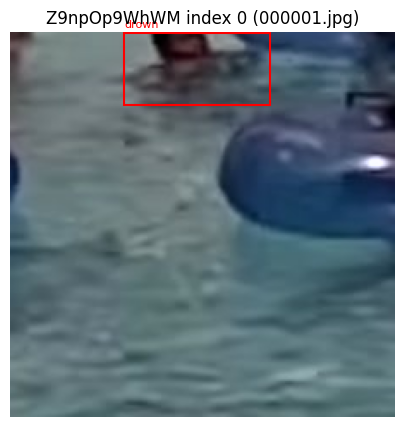

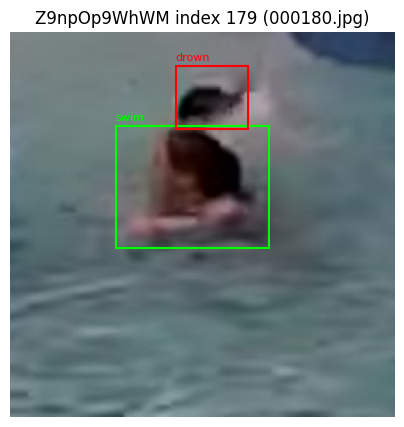

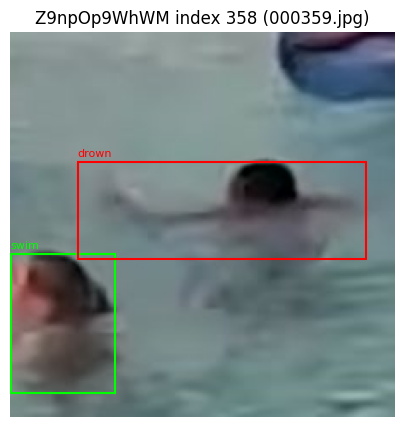

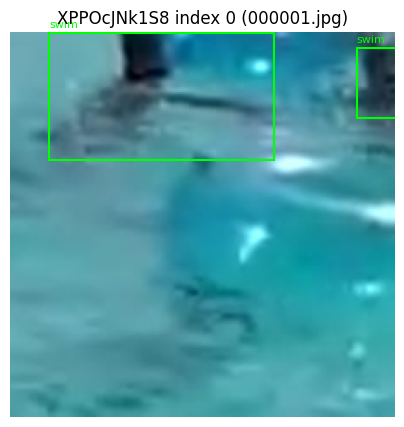

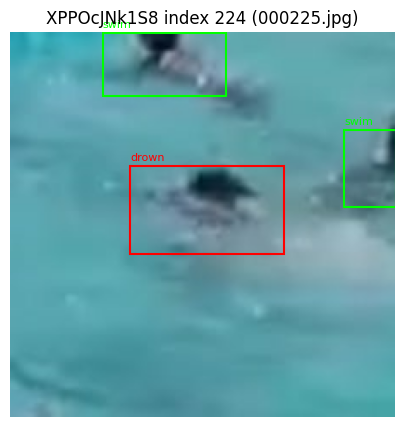

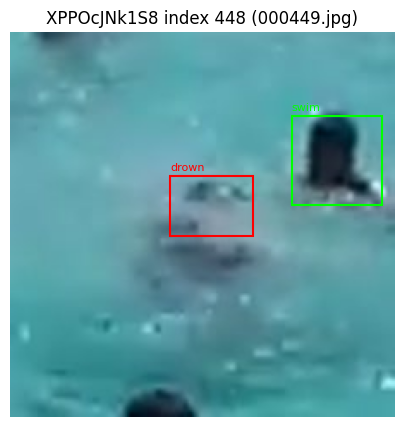

In [18]:
import os, glob, xml.etree.ElementTree as ET
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

BASE = "/content/lifeguard_test"

def show(video, xml_path, indices):
    root = ET.parse(xml_path).getroot()
    by_id = {}
    for im in root.iter("image"):
        by_id[int(im.get("id"))] = [
            (b.get("label"), float(b.get("xtl")), float(b.get("ytl")),
             float(b.get("xbr")), float(b.get("ybr")))
            for b in im.iter("box")]
    frames = sorted(glob.glob(f"{BASE}/frames/{video}/*.jpg"),
                    key=lambda f: int(os.path.splitext(os.path.basename(f))[0]))
    for i in indices:
        img = Image.open(frames[i])
        fig, ax = plt.subplots(1, figsize=(5, 5)); ax.imshow(img)
        for lab, xtl, ytl, xbr, ybr in by_id.get(i, []):
            c = "red" if lab == "drown" else "lime"
            ax.add_patch(Rectangle((xtl, ytl), xbr - xtl, ybr - ytl,
                                   fill=False, edgecolor=c, lw=1.5))
            ax.text(xtl, ytl - 3, lab, color=c, fontsize=8)
        ax.set_title(f"{video} index {i} ({os.path.basename(frames[i])})"); ax.axis("off")
        plt.show()

show("Z9npOp9WhWM", f"{BASE}/annotations/Z9npOp9WhWM_00-00-22--00-00-34_0-04--0-25--0-17.xml", [0, 179, 358])
show("XPPOcJNk1S8", f"{BASE}/annotations/XPPOcJNk1S8_00-00-05--00-00-20_0-70--0-27--0-11.xml", [0, 224, 448])

In [19]:
import os, glob, csv, re, random
BASE = "/content/lifeguard_test"
random.seed(42)

def video_id_of(snippet):
    m = re.match(r"^(.*?)_\d{2}-\d{2}-\d{2}--\d{2}-\d{2}-\d{2}_", snippet)
    return m.group(1) if m else "?"

def read(p):
    with open(p, newline="") as f:
        return list(csv.reader(f))

# 1) canonical clips = full-snippet names only; short-named files are duplicates
xmls = sorted(glob.glob(f"{BASE}/annotations/*.xml"))
canonical = {os.path.splitext(os.path.basename(p))[0] for p in xmls
             if re.search(r"_\d{2}-\d{2}-\d{2}--", os.path.basename(p))}
short = sorted(set(os.path.splitext(os.path.basename(p))[0] for p in xmls) - canonical)
print("Canonical (full-snippet) clips:", len(canonical))
print("Short-named files to ignore (duplicates):", short)

# 2) author's split leakage
train = [r[0] for r in read(f"{BASE}/splitlists/train.csv") if r]
test  = [r[0] for r in read(f"{BASE}/splitlists/test.csv") if r]
tr_v = {video_id_of(c) for c in train}
te_v = {video_id_of(c) for c in test}
print("\nAuthor split: train clips=%d videos=%d | test clips=%d videos=%d"
      % (len(train), len(tr_v), len(test), len(te_v)))
print("Videos in BOTH train and test (leakage):", sorted(tr_v & te_v))

# 3) proposed leak-free VIDEO-level split (reproducible, seed=42)
all_videos = sorted(tr_v | te_v)
test_videos = set(random.sample(all_videos, max(1, round(len(all_videos) * 0.1))))
train_videos = set(all_videos) - test_videos
print("\nProposed leak-free split: train videos=%d, test videos=%d"
      % (len(train_videos), len(test_videos)))
print("Test video ids:", sorted(test_videos))

Canonical (full-snippet) clips: 91
Short-named files to ignore (duplicates): ['XPPOcJNk1S8', 'Z9npOp9WhWM']

Author split: train clips=82 videos=58 | test clips=9 videos=7
Videos in BOTH train and test (leakage): ['IDpdBu-je6E', 'Z9npOp9WhWM', 'hSPOqCbpq1c']

Proposed leak-free split: train videos=56, test videos=6
Test video ids: ['1WIDSrr_1lk', '82PyW_G61MU', 'JYQ9AwsTkAw', 'L0KTqPloUiU', 'n8O__d9ecZs', 'syO6NtNR6xY']


In [20]:
import os, glob, csv, re, random
import xml.etree.ElementTree as ET
BASE = "/content/lifeguard_test"

def video_id_of(snippet):
    m = re.match(r"^(.*?)_\d{2}-\d{2}-\d{2}--\d{2}-\d{2}-\d{2}_", snippet)
    return m.group(1) if m else "?"

def read(p):
    with open(p, newline="") as f:
        return list(csv.reader(f))

# canonical clips only (skip the 2 short-named duplicates)
xmls = sorted(glob.glob(f"{BASE}/annotations/*.xml"))
canonical = {os.path.splitext(os.path.basename(p))[0] for p in xmls
             if re.search(r"_\d{2}-\d{2}-\d{2}--", os.path.basename(p))}

# per-clip: video id + "contains drown?"
videos = {}
for c in canonical:
    root = ET.parse(f"{BASE}/annotations/{c}.xml").getroot()
    has_drown = any(b.get("label") == "drown"
                    for im in root.iter("image") for b in im.iter("box"))
    v = video_id_of(c)
    videos.setdefault(v, {"drown": False, "clips": 0})
    videos[v]["drown"] = videos[v]["drown"] or has_drown
    videos[v]["clips"] += 1

drown_videos    = sorted(v for v, i in videos.items() if i["drown"])
swimonly_videos = sorted(v for v, i in videos.items() if not i["drown"])
print("videos:", len(videos), "| with >=1 drown clip:", len(drown_videos),
      "| swim-only:", len(swimonly_videos))

# stratified, leak-free split: hold out ~10% of EACH group for test
random.seed(42)
def holdout(group):
    n = max(1, round(len(group) * 0.1))
    return set(random.sample(group, n))

test_v = holdout(drown_videos) | holdout(swimonly_videos)
train_v = set(videos) - test_v
print("stratified split: train videos=%d, test videos=%d" % (len(train_v), len(test_v)))
print("test videos containing drown:", sorted(v for v in test_v if videos[v]["drown"]))
print("test videos swim-only:", sorted(v for v in test_v if not videos[v]["drown"]))

videos: 62 | with >=1 drown clip: 55 | swim-only: 7
stratified split: train videos=55, test videos=7
test videos containing drown: ['1WIDSrr_1lk', '9uJazpj9xPw', 'K8mSP7f4ORI', 'NycwxaU4GPw', 'sBlxMGGOpVk', 'vt6ZBq5jVec']
test videos swim-only: ['OAzlohkIVp0']


In [21]:
import os, glob, re, random
import xml.etree.ElementTree as ET
BASE = "/content/lifeguard_test"

def video_id_of(s):
    m = re.match(r"^(.*?)_\d{2}-\d{2}-\d{2}--\d{2}-\d{2}-\d{2}_", s)
    return m.group(1) if m else "?"

clips = {}          # video -> list of per-clip has_drown
unmatched = []
for p in sorted(glob.glob(f"{BASE}/annotations/*.xml")):
    name = os.path.splitext(os.path.basename(p))[0]
    if not re.search(r"_\d{2}-\d{2}-\d{2}--", name):
        continue     # skip the 2 short-named duplicates
    v = video_id_of(name)
    if v == "?":
        unmatched.append(name); continue
    root = ET.parse(p).getroot()
    has_drown = any(b.get("label") == "drown"
                    for im in root.iter("image") for b in im.iter("box"))
    clips.setdefault(v, []).append(has_drown)

print("unmatched clip names (should be []):", unmatched)

random.seed(42)
drown_v = sorted(v for v, l in clips.items() if any(l))
swim_v  = sorted(v for v, l in clips.items() if not any(l))
test_v  = (set(random.sample(drown_v, round(len(drown_v) * 0.1)))
           | set(random.sample(swim_v, round(len(swim_v) * 0.1))))
train_v = set(clips) - test_v

def summary(vset):
    n = d = s = 0
    for v in vset:
        for has_drown in clips[v]:
            n += 1; d += has_drown; s += (not has_drown)
    return n, d, s

for label, vset in [("TRAIN", train_v), ("TEST", test_v)]:
    n, d, s = summary(vset)
    print(f"{label}: videos={len(vset)}  clips={n}  "
          f"drown_containing_clips={d}  swim_only_clips={s}")

unmatched clip names (should be []): []
TRAIN: videos=55  clips=81  drown_containing_clips=49  swim_only_clips=32
TEST: videos=7  clips=10  drown_containing_clips=6  swim_only_clips=4


In [22]:
# Cell 1 — Mount Drive and move the small label/metadata files (and any existing
# videos) into a persistent folder. Idempotent: skips files already present.
from google.colab import drive
import os, shutil, glob

drive.mount('/content/drive')

SRC = "/content/lifeguard_test"                # current temp location (this session)
DST = "/content/drive/MyDrive/lifeguard_test"  # persistent location

os.makedirs(f"{DST}/videos", exist_ok=True)
os.makedirs(f"{DST}/annotations", exist_ok=True)

if os.path.exists(f"{SRC}/datalist.csv") and not os.path.exists(f"{DST}/datalist.csv"):
    shutil.copy(f"{SRC}/datalist.csv", f"{DST}/datalist.csv")
    print("copied datalist.csv -> Drive")

if os.path.exists(f"{SRC}/annotations"):
    n = 0
    for p in glob.glob(f"{SRC}/annotations/*.xml"):
        dst = f"{DST}/annotations/{os.path.basename(p)}"
        if not os.path.exists(dst):
            shutil.copy(p, dst); n += 1
    print(f"copied {n} annotation XMLs -> Drive")

if os.path.exists(f"{SRC}/videos"):
    n = 0
    for p in glob.glob(f"{SRC}/videos/*"):
        dst = f"{DST}/videos/{os.path.basename(p)}"
        if not os.path.exists(dst):
            shutil.copy(p, dst); n += 1
    print(f"copied {n} existing videos -> Drive")

print("Persistent destination:", DST)

Mounted at /content/drive
copied datalist.csv -> Drive
copied 93 annotation XMLs -> Drive
copied 2 existing videos -> Drive
Persistent destination: /content/drive/MyDrive/lifeguard_test


In [23]:
# Cell 2 — Download missing source videos directly into Google Drive.
# Reads datalist.csv + annotations from Drive, skips videos already there,
# and uses --continue so interrupted downloads resume instead of restarting.
import os, csv, glob, subprocess, sys

DST = "/content/drive/MyDrive/lifeguard_test"
VIDEO_DIR = f"{DST}/videos"
DATALIST = f"{DST}/datalist.csv"

if not os.path.exists(DATALIST):
    raise SystemExit("STOP: datalist.csv not in Drive. Run Cell 1 (or the earlier "
                     "GitHub-fetch cells) first.")

def snippet_name(video_id, start, end, x, y, width):
    start = str(start)[:-3].replace(':', '-')
    end   = str(end)[:-3].replace(':', '-')
    x = str(x)[:-2].replace('.', '-')
    y = str(y)[:-2].replace('.', '-')
    width = str(width)[:-2].replace('.', '-')
    return f"{video_id}_{start}--{end}_{x}--{y}--{width}"

needed = set()
with open(DATALIST, newline="") as f:
    for row in csv.reader(f):
        if len(row) < 7:
            continue
        video_id, start, end, x, y, width, flag = row[:7]
        if flag.strip() != "y":
            continue
        if os.path.exists(f"{DST}/annotations/{snippet_name(video_id, start, end, x, y, width)}.xml"):
            needed.add(video_id)

have = {os.path.splitext(os.path.basename(p))[0] for p in glob.glob(f"{VIDEO_DIR}/*")}
to_download = sorted(needed - have)

print(f"source videos needed: {len(needed)} | already in Drive: {len(needed & have)} | to download: {len(to_download)}")

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "yt-dlp"], check=False)

ok, fail = [], []
for v in to_download:
    url = f"https://www.youtube.com/watch?v={v}"
    r = subprocess.run(["yt-dlp", "-f", "bv", "--no-playlist", "--continue",
                        "-o", f"{VIDEO_DIR}/%(id)s.%(ext)s", url])
    if r.returncode == 0:
        ok.append(v); print(f"OK   {v}")
    else:
        fail.append(v); print(f"FAIL {v}  ({url})")

print("\n=== Summary ===")
print("destination:", VIDEO_DIR)
print("downloaded:", len(ok))
print("failed:", len(fail))
for v in fail:
    print("  ", v)

source videos needed: 62 | already in Drive: 2 | to download: 60
OK   0hBJ0gd9T_U
FAIL 1WIDSrr_1lk  (https://www.youtube.com/watch?v=1WIDSrr_1lk)
FAIL 1_l6-wMAvaA  (https://www.youtube.com/watch?v=1_l6-wMAvaA)
OK   4sFuULOY5ik
OK   5YHUlEP7auA
OK   5rxH_ELrwTU
OK   6H8IKoacICU
FAIL 82PyW_G61MU  (https://www.youtube.com/watch?v=82PyW_G61MU)
OK   9uJazpj9xPw
FAIL ALbQbfHaRL0  (https://www.youtube.com/watch?v=ALbQbfHaRL0)
FAIL Bx3qXB5O2fY  (https://www.youtube.com/watch?v=Bx3qXB5O2fY)
OK   H35eyL2M-ng
OK   I-EKqLdbysk
OK   IDpdBu-je6E
OK   IOHBGgt5oG4
OK   JYQ9AwsTkAw
FAIL K8mSP7f4ORI  (https://www.youtube.com/watch?v=K8mSP7f4ORI)
OK   L0KTqPloUiU
OK   NycwxaU4GPw
OK   OAzlohkIVp0
OK   OsmCQeJndVM
OK   PuAfTA2wf7o
OK   Q2t0CJ7Sszs
OK   T5mDQeDkca0
OK   VBgxid77Yzs
OK   Xdu3Kq8bmxc
OK   Y_nXru9bjbA
OK   _bMK1icRofI
OK   aQ6h8U-rqZ4
OK   e7ZJAC62_og
OK   gY0ASobuVok
OK   hSPOqCbpq1c
OK   i5v_ygxv-8M
OK   iVMA7GhSJjM
OK   iXFgOBjk860
OK   jz1qXpZotbc
OK   lcB1184hw30
OK   lvS0S6X3_xc
OK   n8

In [24]:
# Cell — Retry only the 10 failed videos (does not touch the 50 already downloaded).
import os, glob, subprocess, sys

VIDEO_DIR = "/content/drive/MyDrive/lifeguard_test/videos"
FAILED = ["1WIDSrr_1lk", "1_l6-wMAvaA", "82PyW_G61MU", "ALbQbfHaRL0",
          "Bx3qXB5O2fY", "K8mSP7f4ORI", "syO6NtNR6xY", "uFT1yAicqsk",
          "usWABZrI75M", "zuZIfy4aBEY"]

# 1) upgrade yt-dlp (fixes most YouTube format/client breakage)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "yt-dlp"], check=False)

def reason(stderr):
    for kw in ("unavailable", "private", "removed", "region", "age", "sign in",
               "copyright", "members-only", "not available"):
        for line in stderr.splitlines():
            if kw in line.lower():
                return line.strip()
    return "no clear reason (transient network or format)"

ok, fail = [], []
for v in FAILED:
    files = glob.glob(f"{VIDEO_DIR}/{v}.*")
    big = [f for f in files if not f.endswith(".part") and os.path.getsize(f) > 1_000_000]
    if big:
        print(f"SKIP {v}  (already have {os.path.basename(big[0])})")
        continue
    # remove incomplete leftovers so they are never mistaken for completed downloads
    for f in files:
        os.remove(f); print(f"removed incomplete: {os.path.basename(f)}")

    r = subprocess.run(
        ["yt-dlp",
         "-f", "bv*[ext=mp4]/bv*[ext=webm]/bv/b",   # mp4 video -> webm video -> any video -> best
         "--no-playlist", "--continue", "--retries", "3",
         "-o", f"{VIDEO_DIR}/%(id)s.%(ext)s",
         f"https://www.youtube.com/watch?v={v}"],
        capture_output=True, text=True)

    if r.returncode == 0:
        ok.append(v); print(f"OK   {v}")
    else:
        fail.append(v); print(f"FAIL {v}  — {reason(r.stderr)}")

print("\n=== Result ===")
print("succeeded:", len(ok))
print("still failing:", len(fail))
for v in fail:
    print("  ", v)

FAIL 1WIDSrr_1lk  — no clear reason (transient network or format)
FAIL 1_l6-wMAvaA  — no clear reason (transient network or format)
FAIL 82PyW_G61MU  — no clear reason (transient network or format)
FAIL ALbQbfHaRL0  — no clear reason (transient network or format)
FAIL Bx3qXB5O2fY  — ERROR: [youtube] Bx3qXB5O2fY: Please sign in. This helps protect our community. Use --cookies-from-browser or --cookies for the authentication. See  https://github.com/yt-dlp/yt-dlp/wiki/FAQ#how-do-i-pass-cookies-to-yt-dlp  for how to manually pass cookies. Also see  https://github.com/yt-dlp/yt-dlp/wiki/Extractors#exporting-youtube-cookies  for tips on effectively exporting YouTube cookies
FAIL K8mSP7f4ORI  — ERROR: [youtube] K8mSP7f4ORI: Please sign in. This helps protect our community. Use --cookies-from-browser or --cookies for the authentication. See  https://github.com/yt-dlp/yt-dlp/wiki/FAQ#how-do-i-pass-cookies-to-yt-dlp  for how to manually pass cookies. Also see  https://github.com/yt-dlp/yt-dlp/w

In [25]:
# Cell — Diagnose the 10 failures without downloading (--simulate).
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "yt-dlp"], check=False)

IDS = ["1WIDSrr_1lk", "1_l6-wMAvaA", "82PyW_G61MU", "ALbQbfHaRL0",
       "Bx3qXB5O2fY", "K8mSP7f4ORI", "syO6NtNR6xY", "uFT1yAicqsk",
       "usWABZrI75M", "zuZIfy4aBEY"]

for v in IDS:
    r = subprocess.run(
        ["yt-dlp", "--simulate", "--no-playlist",
         f"https://www.youtube.com/watch?v={v}"],
        capture_output=True, text=True)
    lines = (r.stderr or r.stdout).strip().splitlines()
    print(f"--- {v} (exit {r.returncode}) ---")
    for ln in lines[-3:]:
        print("   ", ln)

--- 1WIDSrr_1lk (exit 0) ---
--- 1_l6-wMAvaA (exit 0) ---
--- 82PyW_G61MU (exit 0) ---
--- ALbQbfHaRL0 (exit 0) ---
--- Bx3qXB5O2fY (exit 1) ---
    ERROR: [youtube] Bx3qXB5O2fY: Please sign in. This helps protect our community. Use --cookies-from-browser or --cookies for the authentication. See  https://github.com/yt-dlp/yt-dlp/wiki/FAQ#how-do-i-pass-cookies-to-yt-dlp  for how to manually pass cookies. Also see  https://github.com/yt-dlp/yt-dlp/wiki/Extractors#exporting-youtube-cookies  for tips on effectively exporting YouTube cookies
--- K8mSP7f4ORI (exit 1) ---
    ERROR: [youtube] K8mSP7f4ORI: Please sign in. This helps protect our community. Use --cookies-from-browser or --cookies for the authentication. See  https://github.com/yt-dlp/yt-dlp/wiki/FAQ#how-do-i-pass-cookies-to-yt-dlp  for how to manually pass cookies. Also see  https://github.com/yt-dlp/yt-dlp/wiki/Extractors#exporting-youtube-cookies  for tips on effectively exporting YouTube cookies
--- syO6NtNR6xY (exit 0) ---
-

In [26]:
# Cell — Fix the 7 non-auth failures: install deno (YouTube's JS runtime), then retry.
import os, glob, subprocess, sys

VIDEO_DIR = "/content/drive/MyDrive/lifeguard_test/videos"
RETRY = ["1WIDSrr_1lk", "1_l6-wMAvaA", "82PyW_G61MU", "ALbQbfHaRL0",
         "syO6NtNR6xY", "uFT1yAicqsk", "usWABZrI75M"]   # exclude the 3 auth-gated

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "yt-dlp"], check=False)

# install deno (the JS runtime yt-dlp needs to decrypt YouTube formats)
subprocess.run("curl -fsSL https://deno.land/install.sh | sh", shell=True, check=False)
os.environ["PATH"] = os.path.expanduser("~/.deno/bin") + ":" + os.environ["PATH"]

def complete_file(vid):
    for f in glob.glob(f"{VIDEO_DIR}/{vid}.*"):
        if not f.endswith(".part") and os.path.getsize(f) > 1_000_000:
            return f
    return None

ok, fail = [], []
for v in RETRY:
    done = complete_file(v)
    if done:
        print(f"SKIP {v}  (already have {os.path.basename(done)})"); continue
    r = subprocess.run(
        ["yt-dlp", "-f", "bv*[ext=mp4]/bv*[ext=webm]/bv/b",
         "--no-playlist", "--continue", "--retries", "3",
         "-o", f"{VIDEO_DIR}/%(id)s.%(ext)s",
         f"https://www.youtube.com/watch?v={v}"],
        capture_output=True, text=True)
    if r.returncode == 0 and complete_file(v):
        ok.append(v); print(f"OK   {v}")
    else:
        fail.append(v); print(f"FAIL {v}")
        tail = (r.stderr or r.stdout or "").strip().splitlines()
        if tail: print("   ", tail[-1])

print("\nsucceeded:", len(ok), "| still failing:", len(fail), fail)

FAIL 1WIDSrr_1lk
    ERROR: unable to download video data: HTTP Error 403: Forbidden
OK   1_l6-wMAvaA
FAIL 82PyW_G61MU
    ERROR: unable to download video data: HTTP Error 403: Forbidden
FAIL ALbQbfHaRL0
    ERROR: unable to download video data: HTTP Error 403: Forbidden
FAIL syO6NtNR6xY
    ERROR: unable to download video data: HTTP Error 403: Forbidden
FAIL uFT1yAicqsk
    ERROR: unable to download video data: HTTP Error 403: Forbidden
FAIL usWABZrI75M
    ERROR: unable to download video data: HTTP Error 403: Forbidden

succeeded: 1 | still failing: 6 ['1WIDSrr_1lk', '82PyW_G61MU', 'ALbQbfHaRL0', 'syO6NtNR6xY', 'uFT1yAicqsk', 'usWABZrI75M']


In [27]:
# Cell — Retry the 6 remaining videos with the Android player client
# (YouTube 403-blocks the default web client from Colab's datacenter IP).
import os, glob, subprocess, sys

VIDEO_DIR = "/content/drive/MyDrive/lifeguard_test/videos"
RETRY = ["1WIDSrr_1lk", "82PyW_G61MU", "ALbQbfHaRL0",
         "syO6NtNR6xY", "uFT1yAicqsk", "usWABZrI75M"]

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "yt-dlp"], check=False)
subprocess.run("curl -fsSL https://deno.land/install.sh | sh", shell=True, check=False)
os.environ["PATH"] = os.path.expanduser("~/.deno/bin") + ":" + os.environ["PATH"]

def complete_file(vid):
    for f in glob.glob(f"{VIDEO_DIR}/{vid}.*"):
        if not f.endswith(".part") and os.path.getsize(f) > 1_000_000:
            return f
    return None

ok, fail = [], []
for v in RETRY:
    done = complete_file(v)
    if done:
        print(f"SKIP {v}  (already have {os.path.basename(done)})"); continue
    r = subprocess.run(
        ["yt-dlp",
         "--extractor-args", "youtube:player_client=android",
         "-f", "bv*[ext=mp4]/bv*[ext=webm]/bv/b",
         "--no-playlist", "--continue", "--retries", "3",
         "-o", f"{VIDEO_DIR}/%(id)s.%(ext)s",
         f"https://www.youtube.com/watch?v={v}"],
        capture_output=True, text=True)
    if r.returncode == 0 and complete_file(v):
        ok.append(v); print(f"OK   {v}")
    else:
        fail.append(v); print(f"FAIL {v}")
        tail = (r.stderr or r.stdout or "").strip().splitlines()
        if tail: print("   ", tail[-1])

print("\nsucceeded:", len(ok), "| still failing:", len(fail), fail)

OK   1WIDSrr_1lk
OK   82PyW_G61MU
OK   ALbQbfHaRL0
OK   syO6NtNR6xY
OK   uFT1yAicqsk
FAIL usWABZrI75M
    ERROR: unable to download video data: HTTP Error 416: Requested range not satisfiable

succeeded: 5 | still failing: 1 ['usWABZrI75M']


In [29]:
# Cell — Try alternate player clients for usWABZrI75M (SABR-only streaming workaround).
import os, glob, subprocess, sys

VIDEO_DIR = "/content/drive/MyDrive/lifeguard_test/videos"
VID = "usWABZrI75M"

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "yt-dlp"], check=False)
subprocess.run("curl -fsSL https://deno.land/install.sh | sh", shell=True, check=False)
os.environ["PATH"] = os.path.expanduser("~/.deno/bin") + ":" + os.environ["PATH"]

def done():
    for f in glob.glob(f"{VIDEO_DIR}/{VID}.*"):
        if not f.endswith(".part") and os.path.getsize(f) > 1_000_000:
            return f
    return None

CLIENTS = ["tv", "mweb", "ios", "web_embedded"]

got = False
for client in CLIENTS:
    if done():
        got = True; break
    for f in glob.glob(f"{VIDEO_DIR}/{VID}*.part"):
        os.remove(f)
    r = subprocess.run(
        ["yt-dlp",
         "--extractor-args", f"youtube:player_client={client}",
         "-f", "bv*[ext=mp4]/bv*[ext=webm]/bv/b",
         "--no-playlist", "--no-continue",
         "-o", f"{VIDEO_DIR}/%(id)s.%(ext)s",
         f"https://www.youtube.com/watch?v={VID}"],
        capture_output=True, text=True)
    if r.returncode == 0 and done():
        print(f"OK {VID}  (via client {client})"); got = True; break
    else:
        print(f"FAIL via {client}")
        tail = (r.stderr or r.stdout or "").strip().splitlines()
        if tail: print("   ", tail[-1])

if not got:
    print(f"\n{VID} could not be downloaded by any client.")

FAIL via tv
    ERROR: [youtube] usWABZrI75M: The page needs to be reloaded.
FAIL via mweb
    ERROR: unable to download video data: HTTP Error 403: Forbidden
FAIL via ios
    ERROR: [youtube] usWABZrI75M: Requested format is not available. Use --list-formats for a list of available formats
FAIL via web_embedded
    ERROR: unable to download video data: HTTP Error 403: Forbidden

usWABZrI75M could not be downloaded by any client.


In [30]:
import os, csv, glob

DST = "/content/drive/MyDrive/lifeguard_test"

def snippet_name(video_id, start, end, x, y, width):
    start = str(start)[:-3].replace(':', '-')
    end   = str(end)[:-3].replace(':', '-')
    x = str(x)[:-2].replace('.', '-')
    y = str(y)[:-2].replace('.', '-')
    width = str(width)[:-2].replace('.', '-')
    return f"{video_id}_{start}--{end}_{x}--{y}--{width}"

needed = set()
with open(f"{DST}/datalist.csv", newline="") as f:
    for row in csv.reader(f):
        if len(row) < 7: continue
        video_id, start, end, x, y, width, flag = row[:7]
        if flag.strip() != "y": continue
        if os.path.exists(f"{DST}/annotations/{snippet_name(video_id, start, end, x, y, width)}.xml"):
            needed.add(video_id)

have = {os.path.splitext(os.path.basename(p))[0]
        for p in glob.glob(f"{DST}/videos/*") if not p.endswith(".part")}
print("needed:", len(needed), "| present:", len(needed & have), "| missing:", sorted(needed - have))

needed: 62 | present: 58 | missing: ['Bx3qXB5O2fY', 'K8mSP7f4ORI', 'usWABZrI75M', 'zuZIfy4aBEY']


In [32]:
import os, glob

print("=== /content ===")
for name in sorted(os.listdir("/content")):
    print("  ", name)

print("\n=== .mp4 files under /content ===")
for p in sorted(glob.glob("/content/**/*.mp4", recursive=True)):
    print("  ", p)

print("\n=== .mp4 files in Drive videos/ ===")
drive_videos = "/content/drive/MyDrive/lifeguard_test/videos"
if os.path.isdir(drive_videos):
    for name in sorted(os.listdir(drive_videos)):
        print("  ", name)
else:
    print("  (not found — Drive may not be mounted)")

=== /content ===
   .config
   drive
   lifeguard_test
   sample_data
   yolo11n.pt

=== .mp4 files under /content ===
   /content/drive/MyDrive/lifeguard_test/videos/0hBJ0gd9T_U.mp4
   /content/drive/MyDrive/lifeguard_test/videos/1WIDSrr_1lk.mp4
   /content/drive/MyDrive/lifeguard_test/videos/1_l6-wMAvaA.mp4
   /content/drive/MyDrive/lifeguard_test/videos/4sFuULOY5ik.mp4
   /content/drive/MyDrive/lifeguard_test/videos/5YHUlEP7auA.mp4
   /content/drive/MyDrive/lifeguard_test/videos/5rxH_ELrwTU.mp4
   /content/drive/MyDrive/lifeguard_test/videos/6H8IKoacICU.mp4
   /content/drive/MyDrive/lifeguard_test/videos/82PyW_G61MU.mp4
   /content/drive/MyDrive/lifeguard_test/videos/9uJazpj9xPw.mp4
   /content/drive/MyDrive/lifeguard_test/videos/ALbQbfHaRL0.mp4
   /content/drive/MyDrive/lifeguard_test/videos/H35eyL2M-ng.mp4
   /content/drive/MyDrive/lifeguard_test/videos/I-EKqLdbysk.mp4
   /content/drive/MyDrive/lifeguard_test/videos/IDpdBu-je6E.mp4
   /content/drive/MyDrive/lifeguard_test/videos/I

In [ ]:
import os
from google.colab import files

DEST = "/content/drive/MyDrive/lifeguard_test/videos"

if not os.path.isdir("/content/drive/MyDrive"):
    print("Google Drive is not mounted. Run this first, then re-run this cell:")
    print("  from google.colab import drive")
    print("  drive.mount('/content/drive')")
else:
    os.makedirs(DEST, exist_ok=True)

    print("Select the four MP4 files to upload...")
    uploaded = files.upload()   # {filename: bytes}

    id_map = {"Bx3qXB5O2fY": "Bx3qXB5O2fY.mp4",
              "K8mSP7f4ORI": "K8mSP7f4ORI.mp4",
              "zuZIfy4aBEY": "zuZIfy4aBEY.mp4"}

    for name, data in uploaded.items():
        target = name
        for vid, newname in id_map.items():
            if vid in name:
                target = newname
                break
        dst = os.path.join(DEST, target)
        if os.path.exists(dst):
            print(f"SKIP (already exists): {dst}")
        else:
            with open(dst, "wb") as f:
                f.write(data)
            print(f"OK   {name}\n     -> {dst}  ({len(data)/1e6:.1f} MB)")

    print("\n=== Final check ===")
    expected = ["Bx3qXB5O2fY.mp4", "K8mSP7f4ORI.mp4", "zuZIfy4aBEY.mp4",
                "Wavepool Lifeguard Rescue 43 - Spot the Drowning!.mp4"]
    missing = []
    for e in expected:
        p = os.path.join(DEST, e)
        status = "PRESENT" if os.path.exists(p) else "MISSING"
        print(f"  {status}  {e}")
        if status == "MISSING":
            missing.append(e)
    if missing:
        print("\nStill missing:", missing)
    else:
        print("\nAll four files are present in", DEST)

Select the four MP4 files to upload...


In [2]:
from pathlib import Path

video_dir = Path("/content/drive/MyDrive/lifeguard_test/videos")

if not video_dir.exists():
    print("ERROR: videos folder not found")
else:
    files = sorted(video_dir.iterdir())

    print(f"Total files: {len(files)}\n")

    for i, file in enumerate(files, 1):
        size_mb = file.stat().st_size / (1024 * 1024)
        status = "INCOMPLETE (.part)" if file.name.endswith(".part") else "OK"

        print(f"{i}. {file.name} | {size_mb:.2f} MB | {status}")

Total files: 59

1. 0hBJ0gd9T_U.mp4 | 43.03 MB | OK
2. 1WIDSrr_1lk.mp4 | 7.76 MB | OK
3. 1_l6-wMAvaA.mp4 | 33.46 MB | OK
4. 4sFuULOY5ik.mp4 | 33.29 MB | OK
5. 5YHUlEP7auA.mp4 | 41.82 MB | OK
6. 5rxH_ELrwTU.mp4 | 19.01 MB | OK
7. 6H8IKoacICU.mp4 | 29.52 MB | OK
8. 82PyW_G61MU.mp4 | 8.64 MB | OK
9. 9uJazpj9xPw.mp4 | 163.50 MB | OK
10. ALbQbfHaRL0.mp4 | 6.55 MB | OK
11. H35eyL2M-ng.mp4 | 41.97 MB | OK
12. I-EKqLdbysk.mp4 | 21.76 MB | OK
13. IDpdBu-je6E.mp4 | 16.68 MB | OK
14. IOHBGgt5oG4.mp4 | 15.16 MB | OK
15. JYQ9AwsTkAw.mp4 | 37.56 MB | OK
16. L0KTqPloUiU.mp4 | 19.95 MB | OK
17. NycwxaU4GPw.mp4 | 24.54 MB | OK
18. OAzlohkIVp0.mp4 | 16.63 MB | OK
19. OsmCQeJndVM.mp4 | 43.40 MB | OK
20. PuAfTA2wf7o.mp4 | 39.41 MB | OK
21. Q2t0CJ7Sszs.mp4 | 23.28 MB | OK
22. T5mDQeDkca0.mp4 | 54.73 MB | OK
23. VBgxid77Yzs.mp4 | 63.62 MB | OK
24. XPPOcJNk1S8.mp4 | 21.14 MB | OK
25. Xdu3Kq8bmxc.mp4 | 86.24 MB | OK
26. Y_nXru9bjbA.mp4 | 23.75 MB | OK
27. Z9npOp9WhWM.mp4 | 24.43 MB | OK
28. _bMK1icRofI.mp4 | 

In [6]:

import os
import shutil
from google.colab import drive

# 1) Mount Google Drive
drive.mount("/content/drive")

# 2) API key: paste your NEW Roboflow key here
api_key = "1KYNQ036QaTVoQm0t706"

# 3) Destination + no-overwrite guard
DEST = "/content/drive/MyDrive/lifeguard_datasets/DrowningDetectionTracking_v1"

if os.path.exists(DEST):
    if not os.path.isdir(DEST):
        raise SystemExit(f"STOP: {DEST} exists but is not a folder.")
    if os.listdir(DEST):
        raise SystemExit(f"STOP: {DEST} already exists and is not empty.")
    os.rmdir(DEST)

# 4) Install Roboflow
!pip -q install roboflow

from roboflow import Roboflow

# 5) Download Version 1 in YOLOv11 format
rf = Roboflow(api_key=api_key)
project = rf.workspace("drowningdetection-2zzxz").project(
    "drowningdetectiontracking"
)
version = project.version(1)

try:
    dataset = version.download("yolov11")
except Exception as e:
    raise SystemExit(
        f"STOP: download failed ({type(e).__name__}): {e}"
    )

# 6) Move dataset to Google Drive
os.makedirs(os.path.dirname(DEST), exist_ok=True)
shutil.move(os.path.abspath(dataset.location), DEST)

# 7) Verify the downloaded dataset
print("Dataset saved at:", DEST)
print("data.yaml:", os.path.exists(os.path.join(DEST, "data.yaml")))

for split in ("train", "valid", "test"):
    print(
        split,
        "-> images:", os.path.isdir(f"{DEST}/{split}/images"),
        "| labels:", os.path.isdir(f"{DEST}/{split}/labels")
    )


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 378.3/378.3 kB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 123.2 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.4 MB/s eta 0:00:00
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to DrowningDetectionTracking-1 in yolov11:: 100%|██████████| 47184/47184 [00:04<00:00, 9578.82it/s] 


Dataset saved at: /content/drive/MyDrive/lifeguard_datasets/DrowningDetectionTracking_v1
data.yaml: True
train -> images: True | labels: True
valid -> images: True | labels: True
test -> images: True | labels: True


In [7]:
import os

DRIVE = "/content/drive/MyDrive"

print("=== Top level of MyDrive ===")
try:
    for name in sorted(os.listdir(DRIVE)):
        p = os.path.join(DRIVE, name)
        print(f"  [{'DIR ' if os.path.isdir(p) else 'FILE'}]  {name}")
except Exception as e:
    print("  ERROR reading MyDrive:", e)

def tree(path, depth=0, maxdepth=4):
    if depth > maxdepth:
        return
    try:
        entries = sorted(os.listdir(path))
    except Exception as e:
        print("  " * depth + f"(unreadable: {e})")
        return
    dirs = [e for e in entries if os.path.isdir(os.path.join(path, e))]
    files = [e for e in entries if not os.path.isdir(os.path.join(path, e))]
    fsize = sum(os.path.getsize(os.path.join(path, f)) for f in files)
    print("  " * depth + f"{os.path.basename(path.rstrip('/')) or path}/  "
          f"[{len(dirs)} dirs, {len(files)} files, {fsize/1e6:.1f} MB]")
    if len(files) <= 15:  # list files only when few, to keep output small
        for f in files:
            sz = os.path.getsize(os.path.join(path, f))
            size = f"{sz/1e6:.2f} MB" if sz >= 1e6 else f"{sz/1e3:.0f} KB"
            print("  " * (depth + 1) + f"{f}  ({size})")
    for d in dirs:
        tree(os.path.join(path, d), depth + 1, maxdepth)

# Scan every top-level folder whose name looks dataset-related
roots = []
for n in sorted(os.listdir(DRIVE)):
    p = os.path.join(DRIVE, n)
    if os.path.isdir(p) and any(k in n.lower() for k in ("dataset", "lifeguard", "drown", "sea", "mob")):
        roots.append(p)

for r in roots:
    print(f"\n=== {r} ===")
    tree(r)

print("\n=== Search for dataset marker files (data.yaml / dataset.yaml / *.zip / annotations*.json) ===")
for root, dirs, files in os.walk(DRIVE):
    dirs[:] = [d for d in dirs if d not in (".Trash", ".ipynb_checkpoints")]
    for f in files:
        if (f == "data.yaml" or f == "dataset.yaml" or f.endswith(".zip")
                or f.startswith("annotations") and f.endswith(".json")
                or f == "datalist.csv"):
            print("  ", os.path.join(root, f))

=== Top level of MyDrive ===
  [FILE]  01.docx
  [FILE]  02.docx
  [FILE]  03.docx
  [FILE]  04.docx
  [FILE]  05.docx
  [FILE]  06.docx
  [FILE]  33 Spreadsheet Projects.gsheet
  [FILE]  72380943-986A-4A60-8E81-6E8359E0755B.jpeg
  [FILE]  AI__Cybersecurity_Report.pdf
  [FILE]  AI_and_Cybersecurity_Report_with_Abstracts_.pdf
  [DIR ]  Colab Notebooks
  [FILE]  IMG_3748.jpeg
  [FILE]  IMG_3749.jpeg
  [FILE]  a7be2e4f-742b-4c80-aecb-27af10e9a99d.jpeg
  [FILE]  bouns task.pdf
  [DIR ]  chatbot
  [DIR ]  lifeguard_datasets
  [DIR ]  lifeguard_test
  [DIR ]  medical_ai_project
  [DIR ]  missedData
  [FILE]  moringa_omega3_zinc_benefits.pdf
  [FILE]  نسخة من Examples (1).docx
  [FILE]  نسخة من Examples.docx

=== /content/drive/MyDrive/lifeguard_datasets ===
lifeguard_datasets/  [1 dirs, 0 files, 0.0 MB]
  DrowningDetectionTracking_v1/  [3 dirs, 3 files, 0.0 MB]
    README.dataset.txt  (0 KB)
    README.roboflow.txt  (1 KB)
    data.yaml  (0 KB)
    test/  [2 dirs, 0 files, 0.0 MB]
      imag

In [8]:
import os, csv, glob
from google.colab import drive
drive.mount("/content/drive")

ZT = "/content/drive/MyDrive/lifeguard_test"

def snippet_name(video_id, start, end, x, y, width):
    start = str(start)[:-3].replace(':', '-'); end = str(end)[:-3].replace(':', '-')
    x = str(x)[:-2].replace('.', '-'); y = str(y)[:-2].replace('.', '-'); width = str(width)[:-2].replace('.', '-')
    return f"{video_id}_{start}--{end}_{x}--{y}--{width}"

expected = set()
with open(f"{ZT}/datalist.csv", newline="") as f:
    for row in csv.reader(f):
        if len(row) < 7: continue
        video_id, start, end, x, y, width, flag = row[:7]
        if flag.strip() != "y": continue
        if os.path.exists(f"{ZT}/annotations/{snippet_name(video_id, start, end, x, y, width)}.xml"):
            expected.add(video_id)

present = {os.path.splitext(os.path.basename(p))[0]
           for p in glob.glob(f"{ZT}/videos/*") if not p.endswith(".part")}
missing = sorted(expected - present)

print("expected videos:", len(expected))
print("present videos:", len(present))
print("MISSING (", len(missing), "):", missing)

print("\n=== MyDrive top level (find the shared-folder shortcut name) ===")
for n in sorted(os.listdir("/content/drive/MyDrive")):
    print("  ", n)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
expected videos: 62
present videos: 58
MISSING ( 4 ): ['Bx3qXB5O2fY', 'K8mSP7f4ORI', 'usWABZrI75M', 'zuZIfy4aBEY']

=== MyDrive top level (find the shared-folder shortcut name) ===
   01.docx
   02.docx
   03.docx
   04.docx
   05.docx
   06.docx
   33 Spreadsheet Projects.gsheet
   72380943-986A-4A60-8E81-6E8359E0755B.jpeg
   AI__Cybersecurity_Report.pdf
   AI_and_Cybersecurity_Report_with_Abstracts_.pdf
   Colab Notebooks
   IMG_3748.jpeg
   IMG_3749.jpeg
   a7be2e4f-742b-4c80-aecb-27af10e9a99d.jpeg
   bouns task.pdf
   chatbot
   lifeguard_datasets
   lifeguard_test
   medical_ai_project
   missedData
   moringa_omega3_zinc_benefits.pdf
   نسخة من Examples (1).docx
   نسخة من Examples.docx


In [9]:
SHARED = "/content/drive/MyDrive/PASTE_SHORTCUT_NAME_HERE"   # edit this

import os, glob
print("=== Shared folder contents ===")
for p in sorted(glob.glob(f"{SHARED}/**/*", recursive=True)):
    if os.path.isfile(p):
        print(f"  {os.path.relpath(p, SHARED)}  ({os.path.getsize(p)/1e6:.1f} MB)")

print("\n=== Candidate matching (missing id -> filename containing it) ===")
for mid in missing:
    hits = [os.path.basename(p) for p in glob.glob(f"{SHARED}/**/*", recursive=True)
            if os.path.isfile(p) and mid in os.path.basename(p)]
    print(f"  {mid}: {'FOUND -> ' + ', '.join(hits) if hits else 'NO unambiguous filename match'}")

=== Shared folder contents ===

=== Candidate matching (missing id -> filename containing it) ===
  Bx3qXB5O2fY: NO unambiguous filename match
  K8mSP7f4ORI: NO unambiguous filename match
  usWABZrI75M: NO unambiguous filename match
  zuZIfy4aBEY: NO unambiguous filename match


In [10]:
CONFIRMED = []   # e.g. ["Bx3qXB5O2fY", "K8mSP7f4ORI", "zuZIfy4aBEY"]  <- only unambiguous ones

import os, shutil, glob
ZT = "/content/drive/MyDrive/lifeguard_test"
SHARED = "/content/drive/MyDrive/PASTE_SHORTCUT_NAME_HERE"

copied, skipped, failed = [], [], []
for mid in CONFIRMED:
    srcs = [p for p in glob.glob(f"{SHARED}/**/*", recursive=True)
            if os.path.isfile(p) and mid in os.path.basename(p)]
    if len(srcs) != 1:
        failed.append((mid, "ambiguous/missing source")); continue
    src = srcs[0]
    dst = f"{ZT}/videos/{mid}.mp4"
    if os.path.exists(dst):
        skipped.append((mid, "already present")); continue
    shutil.copyfile(src, dst)
    (copied if os.path.getsize(dst) > 0 else failed).append((mid, os.path.basename(src)))

print("copied:", copied)
print("skipped:", skipped)
print("failed (needs attention):", failed)

present = {os.path.splitext(os.path.basename(p))[0]
           for p in glob.glob(f"{ZT}/videos/*") if not p.endswith(".part")}
print("videos now:", len(present), "of 62")

copied: []
skipped: []
failed (needs attention): []
videos now: 58 of 62


In [11]:
import os, glob

SHARED = "/content/drive/MyDrive/missedData"

print("=== Contents of", SHARED, "===")
for p in sorted(glob.glob(f"{SHARED}/**/*", recursive=True)):
    if os.path.isfile(p):
        print(f"  {os.path.relpath(p, SHARED)}  ({os.path.getsize(p)/1e6:.1f} MB)")

missing = ["Bx3qXB5O2fY", "K8mSP7f4ORI", "usWABZrI75M", "zuZIfy4aBEY"]
print("\n=== Match missing id -> file ===")
for mid in missing:
    hits = [os.path.basename(p) for p in glob.glob(f"{SHARED}/**/*", recursive=True)
            if os.path.isfile(p) and mid in os.path.basename(p)]
    print(f"  {mid}: {'FOUND -> ' + ', '.join(hits) if hits else 'NO id in filename (needs manual check)'}")

=== Contents of /content/drive/MyDrive/missedData ===
  Wavepool Lifeguard Rescue 43 - Spot the Drowning!.mp4  (55.8 MB)
  YTDown.com_YouTube_Media_Bx3qXB5O2fY_Wavepool-Lifeguard-Rescue-57-Spot-the-Drowning_001_1080p.mp4  (45.1 MB)
  YTDown.com_YouTube_Media_K8mSP7f4ORI_Wavepool-Lifeguard-Rescue-50-Spot-the-Drowning_001_1080p.mp4  (30.4 MB)
  YTDown.com_YouTube_Media_zuZIfy4aBEY_A-5-year-old-child-drowns-in-a-swimming-pool-without-anyone-noticing-Finland_001_480p.mp4  (32.8 MB)

=== Match missing id -> file ===
  Bx3qXB5O2fY: FOUND -> YTDown.com_YouTube_Media_Bx3qXB5O2fY_Wavepool-Lifeguard-Rescue-57-Spot-the-Drowning_001_1080p.mp4
  K8mSP7f4ORI: FOUND -> YTDown.com_YouTube_Media_K8mSP7f4ORI_Wavepool-Lifeguard-Rescue-50-Spot-the-Drowning_001_1080p.mp4
  usWABZrI75M: NO id in filename (needs manual check)
  zuZIfy4aBEY: FOUND -> YTDown.com_YouTube_Media_zuZIfy4aBEY_A-5-year-old-child-drowns-in-a-swimming-pool-without-anyone-noticing-Finland_001_480p.mp4


In [12]:
CONFIRMED = ["Bx3qXB5O2fY", "K8mSP7f4ORI", "zuZIfy4aBEY"]   # NOT usWABZrI75M yet

import os, shutil, glob
ZT = "/content/drive/MyDrive/lifeguard_test"
SHARED = "/content/drive/MyDrive/missedData"

copied, failed = [], []
for mid in CONFIRMED:
    srcs = [p for p in glob.glob(f"{SHARED}/**/*", recursive=True)
            if os.path.isfile(p) and mid in os.path.basename(p)]
    if len(srcs) != 1:
        failed.append((mid, "ambiguous/missing")); continue
    src = srcs[0]; dst = f"{ZT}/videos/{mid}.mp4"
    if os.path.exists(dst):
        print("SKIP", mid, "(already present)"); continue
    shutil.copyfile(src, dst)
    print("OK", mid, "->", dst, f"({os.path.getsize(dst)/1e6:.1f} MB)")

present = {os.path.splitext(os.path.basename(p))[0]
           for p in glob.glob(f"{ZT}/videos/*") if not p.endswith(".part")}
print("videos now:", len(present), "of 62 | still missing:", ["usWABZrI75M"] if "usWABZrI75M" not in present else [])

OK Bx3qXB5O2fY -> /content/drive/MyDrive/lifeguard_test/videos/Bx3qXB5O2fY.mp4 (45.1 MB)
OK K8mSP7f4ORI -> /content/drive/MyDrive/lifeguard_test/videos/K8mSP7f4ORI.mp4 (30.4 MB)
OK zuZIfy4aBEY -> /content/drive/MyDrive/lifeguard_test/videos/zuZIfy4aBEY.mp4 (32.8 MB)
videos now: 61 of 62 | still missing: ['usWABZrI75M']


In [13]:

from pathlib import Path

root = Path("/content/drive/MyDrive")
target = "usWABZrI75M"

print("Searching for:", target)

for path in root.rglob("*"):
    if path.is_file() and target.lower() in path.name.lower():
        print("FOUND:", path, f"({path.stat().st_size / (1024**2):.1f} MB)")


Searching for: usWABZrI75M
FOUND: /content/drive/MyDrive/lifeguard_test/videos/usWABZrI75M.mp4.part (68.8 MB)
FOUND: /content/drive/MyDrive/lifeguard_test/annotations/usWABZrI75M_00-00-00--00-00-56_0-41--0-19--0-24.xml (0.7 MB)
FOUND: /content/drive/MyDrive/lifeguard_test/annotations/usWABZrI75M_00-00-46--00-01-03_0-52--0-21--0-14.xml (0.2 MB)


In [14]:

from pathlib import Path
import subprocess

video = Path(
    "/content/drive/MyDrive/lifeguard_test/videos/"
    "usWABZrI75M.mp4.part"
)

print("Exists:", video.exists())

if video.exists():
    print("Size (MB):", round(video.stat().st_size / (1024**2), 2))

    result = subprocess.run(
        ["ffprobe", "-v", "error",
         "-show_entries", "format=duration,size",
         "-of", "default=noprint_wrappers=1",
         str(video)],
        capture_output=True,
        text=True
    )

    print("FFprobe return code:", result.returncode)
    print("FFprobe output:")
    print(result.stdout or result.stderr or "No output")


Exists: True
Size (MB): 68.79
FFprobe return code: 0
FFprobe output:
duration=124.174050
size=72135611



In [15]:

from pathlib import Path

folder = Path("/content/drive/MyDrive/lifeguard_test/videos")
source = folder / "usWABZrI75M.mp4.part"
destination = folder / "usWABZrI75M.mp4"

if not source.exists():
    print("STOP: source file not found.")
elif destination.exists():
    print("STOP: destination already exists. No changes made.")
else:
    source.rename(destination)
    print("Renamed successfully:", destination.name)
    print("Size (MB):", round(destination.stat().st_size / (1024**2), 2))


Renamed successfully: usWABZrI75M.mp4
Size (MB): 68.79


In [16]:

from pathlib import Path
import subprocess

root = Path("/content/drive/MyDrive/lifeguard_test")
video_dir = root / "videos"
annotation_dir = root / "annotations"

videos = sorted(video_dir.glob("*.mp4"))
video_ids = {p.stem for p in videos}

print("=== VIDEO INVENTORY ===")
print("MP4 videos:", len(videos))
print("Expected:", 62)

print("\n=== VIDEO READABILITY ===")
bad_videos = []

for video in videos:
    result = subprocess.run(
        ["ffprobe", "-v", "error",
         "-show_entries", "format=duration",
         "-of", "default=noprint_wrappers=1:nokey=1",
         str(video)],
        capture_output=True,
        text=True
    )

    if result.returncode != 0 or not result.stdout.strip():
        bad_videos.append(video.name)

print("Unreadable videos:", len(bad_videos))
for name in bad_videos:
    print("  ", name)

print("\n=== ANNOTATION ID CHECK ===")
annotation_ids = {
    p.name.split("_")[0]
    for p in annotation_dir.glob("*.xml")
}

missing_annotations = sorted(video_ids - annotation_ids)
unmatched_annotations = sorted(annotation_ids - video_ids)

print("Video IDs without XML:", len(missing_annotations))
for item in missing_annotations:
    print("  ", item)

print("Annotation IDs without matching video:", len(unmatched_annotations))
for item in unmatched_annotations:
    print("  ", item)

print("\n=== FINAL STATUS ===")
if len(videos) == 62 and not bad_videos:
    print("All 62 MP4 files are readable.")
else:
    print("Needs attention: count mismatch or unreadable videos.")


=== VIDEO INVENTORY ===
MP4 videos: 62
Expected: 62

=== VIDEO READABILITY ===
Unreadable videos: 0

=== ANNOTATION ID CHECK ===
Video IDs without XML: 13
   0hBJ0gd9T_U
   1WIDSrr_1lk
   1_l6-wMAvaA
   5rxH_ELrwTU
   82PyW_G61MU
   Y_nXru9bjbA
   _bMK1icRofI
   e7ZJAC62_og
   i5v_ygxv-8M
   lvS0S6X3_xc
   n8O__d9ecZs
   ofWuFIb_Luw
   rgCVJx_100I
Annotation IDs without matching video: 15
   
   0hBJ0gd9T
   1
   1WIDSrr
   5rxH
   82PyW
   XPPOcJNk1S8.xml
   Y
   Z9npOp9WhWM.xml
   e7ZJAC62
   i5v
   lvS0S6X3
   n8O
   ofWuFIb
   rgCVJx

=== FINAL STATUS ===
All 62 MP4 files are readable.


In [17]:
import os, re, glob

ZT = "/content/drive/MyDrive/lifeguard_test"

def video_id_of(snippet):
    m = re.match(r"^(.*?)_\d{2}-\d{2}-\d{2}--\d{2}-\d{2}-\d{2}_", snippet)
    return m.group(1) if m else None

vids = {os.path.splitext(os.path.basename(p))[0]
        for p in glob.glob(f"{ZT}/videos/*") if not p.endswith(".part")}

xmls = [os.path.splitext(os.path.basename(p))[0]
        for p in glob.glob(f"{ZT}/annotations/*.xml")]
canonical = [x for x in xmls if re.search(r"_\d{2}-\d{2}-\d{2}--", x)]
short = [x for x in xmls if x not in canonical]

xml_vids = {video_id_of(x) for x in canonical if video_id_of(x)}

print("videos:", len(vids))
print("canonical XMLs:", len(canonical), "| short-named duplicates:", short)
print("distinct video IDs in canonical XMLs:", len(xml_vids))
print("videos with NO annotation:", sorted(vids - xml_vids))
print("annotation IDs with NO video:", sorted(xml_vids - vids))

videos: 62
canonical XMLs: 91 | short-named duplicates: ['XPPOcJNk1S8', 'Z9npOp9WhWM']
distinct video IDs in canonical XMLs: 62
videos with NO annotation: []
annotation IDs with NO video: []


In [18]:
import os, subprocess, json, urllib.request, zipfile

# 1) Mount Drive only if not already mounted
from google.colab import drive
if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive")

DEST = "/content/drive/MyDrive/lifeguard_datasets/MOBDrone/MOBDrone_videos.zip"
URL  = "https://zenodo.org/records/5996890/files/MOBDrone_videos.zip?download=1"

# 2) Expected size + md5 from the Zenodo API (verified record 5996890)
api = json.load(urllib.request.urlopen("https://zenodo.org/api/records/5996890"))
meta = next(x for x in api["files"] if x["key"] == "MOBDrone_videos.zip")
EXPECTED_SIZE = meta["size"]                 # 5,455,391,169 bytes
EXPECTED_MD5  = meta["checksum"].split(":")[-1]

os.makedirs(os.path.dirname(DEST), exist_ok=True)

# 3) Inspect existing file — never overwrite
if os.path.exists(DEST):
    size = os.path.getsize(DEST)
    if size == EXPECTED_SIZE:
        bad = zipfile.ZipFile(DEST).testzip()
        if bad is None:
            print("SKIP: complete, valid archive already present.")
            raise SystemExit(0)
        raise SystemExit(f"STOP: existing archive is corrupt (bad entry: {bad}). Delete it and re-run.")
    raise SystemExit(f"STOP: existing file is partial/suspicious ({size}/{EXPECTED_SIZE} bytes). "
                     f"Re-run to resume with wget -c, or delete the file to restart cleanly.")

# 4) Download (resumable) directly to the Drive destination
print("Downloading MOBDrone_videos.zip (resumable)...")
r = subprocess.run(["wget", "-c", "--progress=dot:giga", "-O", DEST, URL])
if r.returncode != 0:
    raise SystemExit("STOP: download failed. Re-run this cell to resume (wget -c).")

# 5) Verify size
size = os.path.getsize(DEST)
print(f"final size: {size} bytes (expected {EXPECTED_SIZE})")
if size != EXPECTED_SIZE:
    raise SystemExit("STOP: size mismatch after download.")

# 6) Verify integrity without extracting (CRC check)
print("Verifying zip integrity (testzip, no extraction)...")
bad = zipfile.ZipFile(DEST).testzip()
if bad is not None:
    raise SystemExit(f"STOP: archive corrupt at entry {bad}.")
print("OK: archive downloaded and verified.")
print("Optional md5 (slow on 5.5 GB):", EXPECTED_MD5)

final size: 5455391169 bytes (expected 5455391169)
Verifying zip integrity (testzip, no extraction)...
OK: archive downloaded and verified.
Optional md5 (slow on 5.5 GB): 250c19fdd6fb0b5aa5fa43e5ad140306
